# Mínimos cuadrados mediante métodos iterativos

Resolveremos nuevamente el problema de mínimos cuadrados para $A_7$ y las mediciones ruidosas $b_\sigma$, pero esta vez utilizando métodos iterativos. Definimos la función objetivo como:

$$E(x) = \frac{1}{2}\,\|A_7 x - b_\sigma\|^2$$

Para este costo, utilizaremos el gradiente $\nabla E(x) = A_7^T(A_7 x - b_\sigma)$ y la Hessiana constante $H = A_7^TA_7$.

Se usan las mediciones con $\sigma = 0.06$, las mismas del Ejercicio 7.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Fantoma del ejercicio 1 (matriz y vector)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_v_fantoma = X_fantoma.reshape(-1)
norma_fantoma = np.linalg.norm(x_v_fantoma)


# Funciones de los ejercicios 2 y 3 (copiadas para que el notebook sea autocontenido)
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n))
    i, j = np.ogrid[:n, :n]
    condicion = (i * direccion[0] + j * direccion[1] == s)   # píxeles cuyo centro cumple α·i + β·j = s
    M[condicion] = 1
    return M


def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n, n))
    filas = []    # filas de A, una por rayo
    rayos = []    # par ((α, β), s) de cada fila
    for (alfa, beta) in direcciones:
        S = alfa * i + beta * j               # a qué rayo pertenece cada píxel
        for s in np.unique(S):                # cada valor distinto de s es un rayo
            M = mascara_rayo(n, (alfa, beta), s)
            filas.append(M.reshape(-1))       # máscara vectorizada -> fila de A
            rayos.append(((alfa, beta), int(s)))
    A = np.array(filas, dtype=float)
    return A, rayos


# Matriz A7 del ejercicio 4 y mediciones ideales
D7 = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1), (1, 2), (3, 1)]
A7, rayos7 = matriz_proyeccion(8, D7)
b7 = A7 @ x_v_fantoma

# Mismo vector z y misma escala del ejercicio 6 (misma semilla)
rng = np.random.default_rng(42)
z = rng.standard_normal(b7.shape[0])
escala = np.sqrt(np.mean(b7**2))


# Mediciones con ruido sigma = 0.06 (las del ejercicio 7)
sigma = 0.06
b_sigma = b7 + sigma * escala * z

#### a) Interpretar las expresiones provistas e implementar funciones que calculen $E(x)$ y $\nabla E(x)$. Construir también $H$ y verificar numéricamente que es simétrica.

In [2]:

#Función de costo
def costo(x):
    # E(x) = 1/2 ||A7 x - b_sigma||^2
    return 0.5 * np.linalg.norm(A7 @ x - b_sigma)**2


def gradiente(x):
    # ∇E(x) = A7ᵀ (A7 x - b_sigma)
    return A7.T @ (A7 @ x - b_sigma)


# Hessiana, matriz de segundas derivadas
H = A7.T @ A7
print("Dimensión de H:", H.shape)
print("¿H es simétrica?", np.allclose(H, H.T))

Dimensión de H: (64, 64)
¿H es simétrica? True


$E(x)$ es la mitad del cuadrado de la distancia entre las mediciones que produciría la imagen $x$ ($A_7 x$) y las mediciones con ruido ($b_\sigma$). Es decir, Para cada imagen $x$, mide qué tan lejos están sus mediciones ($A_7 x$) de las mediciones reales ($b_\sigma$). Encontrar la mejor imagen es encontrar la $x$ donde $E$ es mínimo.

El gradiente $\nabla E(x)$ es el vector de derivadas parciales de $E$ e indica la dirección en la que el costo crece más rápido. Por eso, para bajar el costo hay que moverse en la dirección contraria. Además, $\nabla E(x) = 0$ es lo mismo que $A_7^TA_7 x = A_7^T b_\sigma$, es decir, el mínimo de $E$ es la solución de mínimos cuadrados.

La Hessiana $H$ es la matriz de segundas derivadas de $E$. describe qué tan empinada es la curvatura en cada dirección. Como $E$ es una función cuadrática, sus segundas derivadas no dependen de $x$, por lo que $H = A_7^TA_7$ es constante. Además, $H$ es simétrica, porque $(A_7^TA_7)^T = A_7^T(A_7^T)^T = A_7^TA_7$.

#### b) Implementar gradiente descendiente mediante $x_{t+1} = x_t - \alpha\,\nabla E(x_t)$, comenzando con $x_0 = 0$. Registrar el costo y la norma del gradiente durante las iteraciones.

Tasa de aprendizaje: alpha = 0.0274
Iteraciones: 708
Costo inicial: 71.3594   Costo final: 0.0616
Norma del gradiente final: 9.99e-07


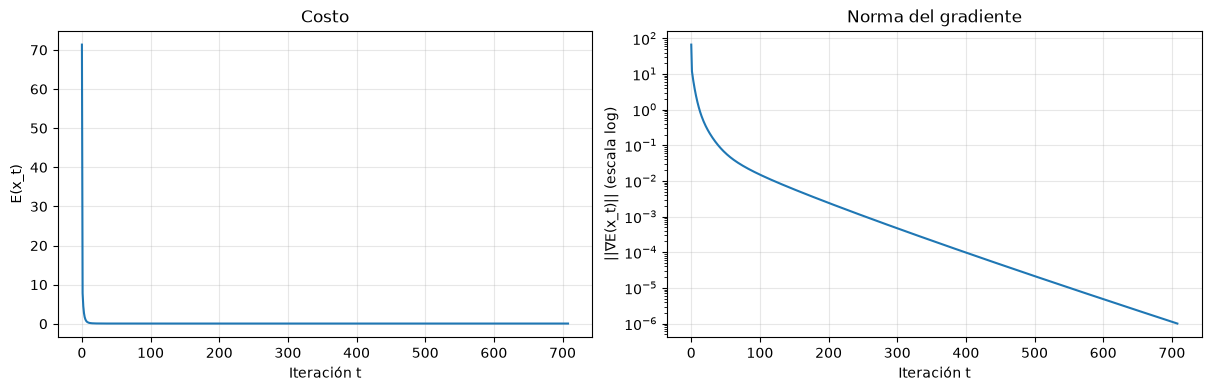

In [3]:
def gradiente_descendiente(alpha, max_iter=5000, tol=1e-6):
    x = np.zeros(A7.shape[1])          # punto inicial x0 = 0 (imagen toda en 0)
    costos = [costo(x)]                # lista de costos E(x_t) en cada iteración
    normas_grad = [np.linalg.norm(gradiente(x))]

    for t in range(max_iter):           #Limite de iteraciones, por si no converge
        g = gradiente(x)
        if np.linalg.norm(g) < tol:     # Si el gradiente es casi 0
            break                       # Se detiene la iteración
        x = x - alpha * g               # Sino se avanza en la dirección contraria al gradiente
        costos.append(costo(x))
        normas_grad.append(np.linalg.norm(gradiente(x)))  # Se guarda la norma del gradiente para analizar la convergencia

    return x, np.array(costos), np.array(normas_grad)  

# Tasa de aprendizaje dentro del intervalo de convergencia (0, 2/mu_max)
mu_max = np.linalg.eigvalsh(H).max()
alpha = 1 / mu_max


x_gd, costos_gd, normas_grad_gd = gradiente_descendiente(alpha)

print(f"Tasa de aprendizaje: alpha = {alpha:.4f}")
print(f"Iteraciones: {len(costos_gd) - 1}")   # -1 porque la primera iteración es el costo inicial
print(f"Costo inicial: {costos_gd[0]:.4f}   Costo final: {costos_gd[-1]:.4f}")
print(f"Norma del gradiente final: {normas_grad_gd[-1]:.2e}")


#gráfico de costo 
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
axes[0].plot(costos_gd)
axes[0].set_xlabel('Iteración t')
axes[0].set_ylabel('E(x_t)')
axes[0].set_title('Costo')
axes[0].grid(alpha=0.3)

#gráfico de norma del gradiente
axes[1].semilogy(normas_grad_gd)
axes[1].set_xlabel('Iteración t')
axes[1].set_ylabel('||∇E(x_t)|| (escala log)')
axes[1].set_title('Norma del gradiente')
axes[1].grid(alpha=0.3)

plt.savefig('figuras/ejercicio_08b.png', dpi=150, bbox_inches='tight')
plt.show()

Se implementó el algoritmo de gradiente descendiente visto en clase, se parte de $x_0 = 0$ y en cada paso se avanza en la dirección contraria al gradiente, con un paso de tamaño $\alpha$. El algoritmo itera hasta que la norma del gradiente es casi 0, es decir, cuando ya prácticamente no hay hacia dónde bajar, o al llegar a un máximo de iteraciones.

Con $\alpha = 1/\mu_{\max}$ (la elección se justifica en el inciso c), el método necesitó 708 iteraciones. El costo baja rápido en las primeras iteraciones y después se estabiliza en su valor mínimo (≈ 0.062), mientras que la norma del gradiente disminuye de forma sostenida hasta llegar al criterio de parada.

En el gráfico de costo se ve que el costo baja rápido al principio y después se aplana. lejos del mínimo la pendiente es grande y los pasos avanzan mucho, cerca del final, la pendiente es cada vez menor por lo que cada paso mejora muy poco.

#### c) Calcular el mayor autovalor $\mu_{\max}$ de $H$ y probar tasas de aprendizaje dentro y fuera del intervalo $0 < \alpha < 2/\mu_{\max}$. Comparar las curvas del costo y describir cuándo el método converge o se vuelve inestable.

mu_max = 36.4634
2 / mu_max = 0.0548

alpha = 0.0137 (dentro del intervalo): costo tras 300 iteraciones = 0.06166
alpha = 0.0274 (dentro del intervalo): costo tras 300 iteraciones = 0.06163
alpha = 0.0521 (dentro del intervalo): costo tras 300 iteraciones = 0.06163
alpha = 0.0562 (fuera del intervalo): costo tras 300 iteraciones = 2.944e+14


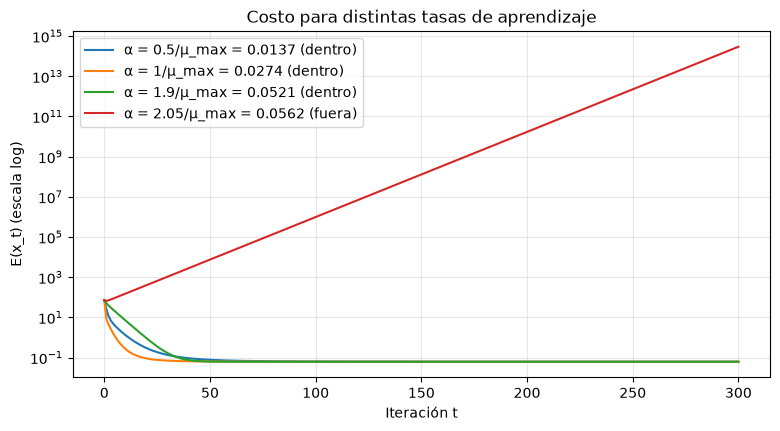

In [4]:
autovalores = np.linalg.eigvalsh(H)    # Autovalores de H, matriz simétrica
mu_max = autovalores.max()             # Dirección más empinada de la función de costo (mayor curvatura)
print(f"mu_max = {mu_max:.4f}")       
print(f"2 / mu_max = {2 / mu_max:.4f}\n") #Limite del intervalo estable

# alpha = factor / mu_max
# Si el factor es menor a 2, la tasa de aprendizaje está dentro del intervalo de convergencia (0, 2/mu_max)
# Si el factor es mayor a 2, la tasa de aprendizaje está fuera del intervalo de convergencia
factores = [0.5, 1, 1.9, 2.05]          
fig, ax = plt.subplots(figsize=(9, 4.5))

for f in factores:
    a = f / mu_max

    # Se ejecuta el gradiente descendiente con la tasa de aprendizaje a 
    # tol = 0 para que no se detenga por el criterio de gradiente casi nulo, sino que se ejecute hasta max_iter
    _, costos, _ = gradiente_descendiente(a, max_iter=300, tol=0)

    dentro = "dentro" if a < 2 / mu_max else "fuera"
    ax.semilogy(costos, label=f'α = {f}/μ_max = {a:.4f} ({dentro})')  # Al ser en escala logarítmica, el costo crece muchisimo si α está fuera del intervalo de convergencia
    print(f"alpha = {a:.4f} ({dentro} del intervalo): costo tras 300 iteraciones = {costos[-1]:.4g}")

ax.set_xlabel('Iteración t')
ax.set_ylabel('E(x_t) (escala log)')
ax.set_title('Costo para distintas tasas de aprendizaje')
ax.legend()
ax.grid(alpha=0.3)
plt.savefig('figuras/ejercicio_08c.png', dpi=150, bbox_inches='tight')
plt.show()

Como $H$ es simétrica, sus 64 autovalores son reales. El mayor es $\mu_{\max} \approx 36.46$, que corresponde a la dirección en la que el costo es más empinado. Reemplazando en la condición que da la consigna

$$0 < \alpha < \frac{2}{\mu_{\max}} = \frac{2}{36.46} \approx 0.0548$$

Es decir, cualquier tasa de aprendizaje menor que 0.0548 debería hacer converger al método, y cualquiera mayor, hacerlo inestable. Para comprobarlo, se probaron tasas de la forma $\alpha = c/\mu_{\max}$ con $c = 0.5$, $1$ y $1.9$ (todas menores que 2, es decir, dentro del intervalo) y con $c = 2.05$ (fuera del intervalo).


- **Dentro del intervalo** ($\alpha = 0.5/\mu_{\max}$, $1/\mu_{\max}$ y $1.9/\mu_{\max}$) el costo baja en todos los casos hasta el mismo valor mínimo, es decir, el método converge. Lo que cambia es la velocidad en que lo hacen.
- **Fuera del intervalo** ($\alpha = 2.05/\mu_{\max}$), el costo, en lugar de bajar, crece sin control, es decir, el método se vuelve inestable y diverge.

Esto demuestra que si $\alpha$ es demasiado chico el algoritmo avanza muy lento, y si es demasiado grande los pasos se pueden "pasar" del mínimo y el algoritmo puede no converger nunca. El valor $2/\mu_{\max}$ marca el límite entre los dos comportamientos m$\mu_{\max}$ indica la dirección en la que el costo es más empinado. En esa dirección, un paso mayor a $2/\mu_{\max}$ terminaria más lejos del mínimo que donde empezó.


#### d) Implementar el método de Newton resolviendo $H\,p_t = \nabla E(x_t)$ mediante `np.linalg.solve` y actualizando $x_{t+1} = x_t - p_t$. Verificar que alcanza la solución en una sola iteración y explicar por qué esto ocurre para una función cuadrática con Hessiana constante.

In [5]:
x0 = np.zeros(A7.shape[1])

# Primera iteración de Newton
p0 = np.linalg.solve(H, gradiente(x0))     # resuelve H p = ∇E(x0)
x_newton = x0 - p0                         # x1= x0 - p0

# Segunda iteración
# Si ya está en el mínimo, el paso debería ser nulo
p1 = np.linalg.solve(H, gradiente(x_newton))

#Solución de referencia usando la función lstsq de numpy, para comparar
x_lstsq, _, _, _ = np.linalg.lstsq(A7, b_sigma, rcond=None)

print(f"||∇E(x1)||          = {np.linalg.norm(gradiente(x_newton)):.2e}")
print(f"||p1|| (2do paso)   = {np.linalg.norm(p1):.2e}")
print(f"||x_newton - x_lstsq|| = {np.linalg.norm(x_newton - x_lstsq):.2e}")

||∇E(x1)||          = 1.54e-14
||p1|| (2do paso)   = 4.53e-15
||x_newton - x_lstsq|| = 5.79e-15


Después de una sola iteración, el gradiente en $x_1$ es prácticamente cero y el segundo paso $p_1$ también, es decir el método ya llegó al mínimo. Además, $x_1$ coincide con la solución de `lstsq`.

Esto ocurre porque el método de Newton aproxima la función con su desarrollo de Taylor de segundo orden y salta directamente al mínimo de esa aproximación. Cuando la función ya es cuadrática, tal como lo es $E(x)$, la cuela no es una aproximación, es  la función. Por lo tanto, el mínimo de la aproximación es el mínimo verdadero, y se alcanza en un solo paso desde cualquier punto inicial.

También se puede ver con las fórmulas. Partiendo de $x_0 = 0$:

$$x_1 = x_0 - H^{-1}\nabla E(x_0) = 0 - (A_7^TA_7)^{-1}A_7^T(A_7\cdot 0 - b_\sigma) = (A_7^TA_7)^{-1}A_7^T b_\sigma$$

que es la solución de las ecuaciones normales de mínimos cuadrados. Para poder hacerlo, $H$ tiene que ser invertible, lo que se cumple porque $A_7$ tiene columnas linealmente independientes.

#### e) Comparar las reconstrucciones obtenidas mediante gradiente descendiente, Newton y `lstsq`.

Método                    Error relativo   ||x - x_lstsq||
Gradiente descendiente            0.0975          1.91e-06
Newton                            0.0975          5.79e-15
lstsq                             0.0975          0.00e+00


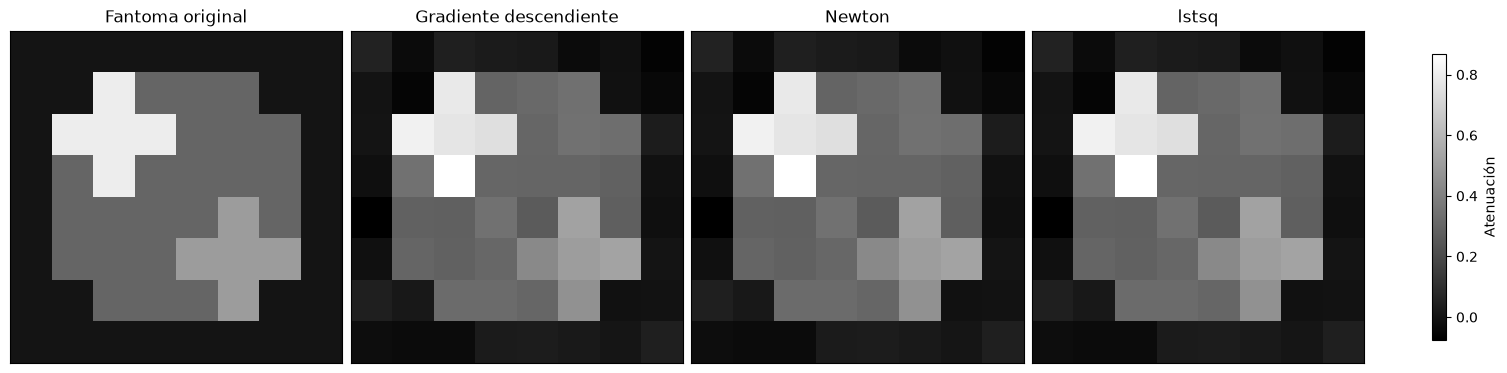

In [7]:
#Reconstrucciones a comparar
soluciones = {'Gradiente descendiente': x_gd, 'Newton': x_newton, 'lstsq': x_lstsq}

# Comparación de errores relativos y diferencias con la solución de referencia
print(f"{'Método':<24}{'Error relativo':>16}{'||x - x_lstsq||':>18}")
for nombre, x in soluciones.items():
    error = np.linalg.norm(x - x_v_fantoma) / norma_fantoma
    print(f"{nombre:<24}{error:>16.4f}{np.linalg.norm(x - x_lstsq):>18.2e}")

imagenes = [X_fantoma] + [x.reshape(8, 8) for x in soluciones.values()]
vmin = min(img.min() for img in imagenes)
vmax = max(img.max() for img in imagenes)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), layout='constrained')
titulos = ['Fantoma original'] + list(soluciones.keys())
for ax, img, titulo in zip(axes, imagenes, titulos):
    im = ax.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label='Atenuación')
plt.savefig('figuras/ejercicio_08e.png', dpi=150, bbox_inches='tight')
plt.show()

Los tres métodos llegan a la misma reconstrucción, las diferencias con `lstsq` son del orden de $10^{-6}$ para gradiente descendiente (que se detuvo cuando el gradiente fue menor que $10^{-6}$) y de $10^{-15}$ para Newton. Por eso las tres tienen el mismo error relativo (≈ 0.0975, el mismo del Ejercicio 6 para $\sigma = 0.06$) y las imágenes son iguales.

Esto tiene sentido, porque los tres resuelven el mismo problema, minimizar $\|A_7 x - b_\sigma\|^2$, que tiene una única solución porque $A_7$ tiene rango completo. Lo unico que cambia es la forma de calcularlo

- **lstsq** resuelve el problema de forma directa, calcula la descomposición SVD de $A_7$ y arma la solución a partir de ella.
- **Gradiente descendiente** se acerca al mínimo de a poco, usando solo el gradiente pero depende de elegir bien $\alpha$.
- **Newton** usa además la Hessiana, y por ser $E$ cuadrática llega en una sola iteración, pero en cada paso tiene que resolver un sistema con $H$.

Este ejercicio muestra que el mismo problema de mínimos cuadrados se puede resolver de distintas formas, y que todas llegan a la misma imagen. La diferencia está en cuánto cuesta llegar. `lstsq` y Newton resuelven el problema de una vez, pero necesitan trabajar con la matriz completa o con la Hessiana, lo que se vuelve muy costoso cuando la imagen es grande. Gradiente descendiente, en cambio, necesita muchas iteraciones, pero en cada una solo multiplica por $A$ y por $A^T$, lo que es mucho más barato, sobre todo cuando $A$ tiene casi todas sus entradas en cero. Por eso es el método que se usa en problemas grandes. A cambio, hay que elegir bien la tasa de aprendizaje.